# 3. Volatility and the learned operators (JPM, paper 1)

Lines the 1-step operator diagnostics up with a 21-day realized variance proxy and with VIX, looks at
where the Chapman-Kolmogorov discrepancy is large, and draws the paper's snapshot and scatter figures.

The first version of this analysis (`_analysis_tasks.py`) built the direct h-step operators with a
different feature list than the models were trained on (it kept the empty `Opinion` column and dropped
`Percent_change_backward`, so every input sat one column off). The h=1 diagnostics were not affected,
but the CK time series and everything computed from it were. This notebook rebuilds them with the
training features.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "markov").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, ttest_ind

from markov.data import load_jpm, returns, splits_by_horizon, standardize, return_states
from markov.models import make_model
from markov.train import operators
from markov.metrics import compose, dobrushin, row_heterogeneity, row_entropy
from markov.plots import save, heatmap

HORIZONS = [1, 2, 5, 10]
SEED = 42
RUN = ROOT / "results/single_asset/paper_run"
OUT = RUN / "volatility"
FIG = RUN / "figures"
DEVICE = torch.device("cpu")

In [2]:
prices, F, cols = load_jpm()
sp = splits_by_horizon(len(prices) - 1, HORIZONS)
F = standardize(F, sp[1]["idx_train"])
X, n_x, _ = return_states(prices, 55, len(sp[1]["idx_train"]))

A = {}
for h in HORIZONS:
    for kind in ["state_cond", "state_free"]:
        model = make_model(kind, F.shape[1], n_x, n_x)
        model.load_state_dict(torch.load(RUN / f"cache/ck_{kind}_h{h}_seed{SEED}.pt", map_location="cpu"))
        A[(kind, h)] = operators(model, F, np.arange(sp[h]["T"]), n_x, n_x, DEVICE, state_free=kind == "state_free")

## Diagnostics of the 1-step state-conditioned operator vs realized variance and VIX

In [3]:
A1 = A[("state_cond", 1)]
T = len(A1)
t = np.arange(T)
diag = pd.DataFrame({"t": t, "dobrushin": dobrushin(A1), "row_hetero": row_heterogeneity(A1), "row_entropy": row_entropy(A1)})
diag.to_csv(OUT / "operator_diagnostics_timeseries.csv", index=False)

# RV_t = variance of the last 21 daily returns, including r_t (the return in X_t)
r = returns(prices, 1)
RV = pd.Series(r).rolling(21).var(ddof=1).values[:T]

# VIX file is newest first with comma decimals, JPM training data starts at row 4032 of the chronological file
vix = pd.read_csv(ROOT / "data/jpm_raw/PriceHistoryVIX.csv")["Price"].str.replace(",", ".").astype(float).values[::-1]
jpm = pd.read_csv(ROOT / "data/jpm_raw/Diagnostic/PriceHistoryJPM.csv")["Price"].values[::-1]
START = 4032
assert np.isclose(jpm[START], prices[0], rtol=1e-3)
VIX = vix[START:START + T]

test = np.isin(t, sp[1]["idx_test"])
rows = []
for proxy, name in [(RV, ""), (VIX, "_vs_VIX")]:
    for m in ["dobrushin", "row_hetero", "row_entropy"]:
        for period, mask in [("full", np.ones(T, bool)), ("test", test)]:
            ok = mask & np.isfinite(proxy)
            r_, p_ = pearsonr(diag[m].values[ok], proxy[ok])
            rows.append({"metric": m + name, "period": period, "pearson_r": r_, "p_value": p_})
corr = pd.DataFrame(rows)
corr.to_csv(OUT / "volatility_correlation.csv", index=False)
pd.DataFrame({"t": t, "dobrushin": diag.dobrushin, "row_hetero": diag.row_hetero, "RV_t": RV, "VIX_t": VIX}).to_csv(
    OUT / "volatility_proxy_timeseries.csv", index=False)
print(corr.round(4).to_string(index=False))

            metric period  pearson_r  p_value
         dobrushin   full    -0.0413   0.0456
         dobrushin   test     0.0699   0.1885
        row_hetero   full    -0.1016   0.0000
        row_hetero   test     0.0637   0.2306
       row_entropy   full    -0.6219   0.0000
       row_entropy   test     0.0490   0.3564
  dobrushin_vs_VIX   full    -0.2013   0.0000
  dobrushin_vs_VIX   test     0.2721   0.0000
 row_hetero_vs_VIX   full    -0.2816   0.0000
 row_hetero_vs_VIX   test     0.2623   0.0000
row_entropy_vs_VIX   full    -0.3326   0.0000
row_entropy_vs_VIX   test     0.3207   0.0000


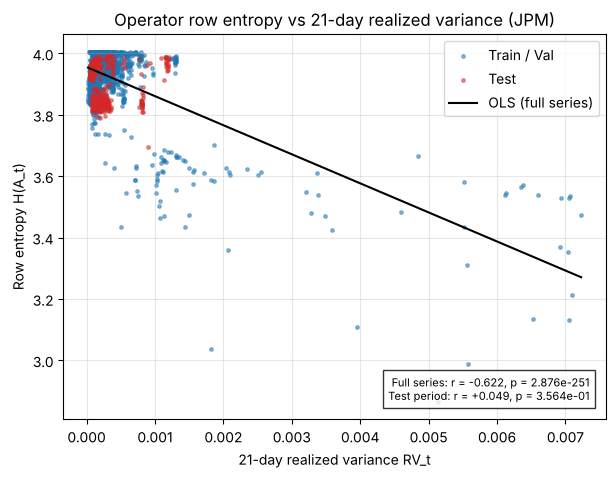

In [4]:
# figure 9: row entropy vs realized variance, colored by split
ok = np.isfinite(RV)
r_full, p_full = pearsonr(diag.row_entropy[ok], RV[ok])
r_test, p_test = pearsonr(diag.row_entropy[ok & test], RV[ok & test])
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(RV[ok & ~test], diag.row_entropy[ok & ~test], s=6, alpha=0.5, label="Train / Val")
ax.scatter(RV[ok & test], diag.row_entropy[ok & test], s=6, alpha=0.5, color="C3", label="Test")
b, a = np.polyfit(RV[ok], diag.row_entropy[ok], 1)
x = np.linspace(np.nanmin(RV), np.nanmax(RV), 100)
ax.plot(x, a + b * x, "k", label="OLS (full series)")
ax.text(0.97, 0.05, f"Full series: r = {r_full:.3f}, p = {p_full:.3e}\nTest period: r = {r_test:+.3f}, p = {p_test:.3e}",
        transform=ax.transAxes, ha="right", fontsize=8, bbox={"facecolor": "white", "alpha": 0.8})
ax.set(xlabel="21-day realized variance RV_t", ylabel="Row entropy H(A_t)", title="Operator row entropy vs 21-day realized variance (JPM)")
ax.legend()
save(fig, FIG / "entropy_vs_realized_variance")
plt.show()

## Chapman-Kolmogorov discrepancy over the full series

KL between the direct h-step operator and the product of the next h one-step operators, averaged over rows
(unweighted, unlike the test-period CK table in notebook 2).

In [5]:
rows = []
for h in HORIZONS[1:]:
    for kind in ["state_cond", "state_free"]:
        P = np.clip(A[(kind, h)].astype(np.float64), 1e-10, None)
        Q = np.clip(compose(A[(kind, 1)], h), 1e-10, None)
        kl = (P * np.log(P / Q)).sum(axis=2).mean(axis=1)
        tv = 0.5 * np.abs(A[(kind, h)] - compose(A[(kind, 1)], h)).sum(axis=2).mean(axis=1)
        rows.append(pd.DataFrame({"t": np.arange(len(kl)), "model": kind, "h": h, "KL_t": kl, "TV_t": tv}))
ck = pd.concat(rows, ignore_index=True)
ck.to_csv(OUT / "ck_timeseries.csv", index=False)
print(ck.groupby(["h", "model"]).KL_t.agg(["mean", "max"]).round(4))

                 mean     max
h  model                     
2  state_cond  0.0946  1.1088
   state_free  0.0590  1.0157
5  state_cond  0.0489  0.5641
   state_free  0.0228  0.5470
10 state_cond  0.0937  1.1011
   state_free  0.0575  0.9960


In [6]:
kl5 = ck[(ck.h == 5) & (ck.model == "state_cond")].set_index("t").KL_t
rows = []
for name, s in [("row_entropy_t", diag.row_entropy), ("dobrushin_t", diag.dobrushin), ("RV_t", pd.Series(RV))]:
    x = s.values[kl5.index]
    ok = np.isfinite(x)
    r_, p_ = pearsonr(kl5.values[ok], x[ok])
    rows.append({"predictor": name, "pearson_r": r_, "p_value": p_})
pd.DataFrame(rows).to_csv(OUT / "ck_volatility_correlation.csv", index=False)
print("CK KL (h=5, state_cond) vs")
print(pd.DataFrame(rows).round(4).to_string(index=False))

CK KL (h=5, state_cond) vs
    predictor  pearson_r  p_value
row_entropy_t    -0.4170      0.0
  dobrushin_t    -0.2755      0.0
         RV_t     0.1682      0.0


## Stressed vs tranquil days (top vs bottom 20% of RV_t)

In [7]:
lo, hi = np.nanpercentile(RV, [20, 80])
stress, calm = RV >= hi, RV <= lo
kl5_full = np.full(T, np.nan)
kl5_full[kl5.index] = kl5.values
rows = []
for name, v in [("dobrushin", diag.dobrushin.values), ("row_hetero", diag.row_hetero.values),
                ("row_entropy", diag.row_entropy.values), ("KL_t_h5_sc", kl5_full)]:
    a, b = v[stress & np.isfinite(v)], v[calm & np.isfinite(v)]
    t_, p_ = ttest_ind(a, b, equal_var=False)
    rows.append({"metric": name, "high_vol_mean": a.mean(), "high_vol_std": a.std(ddof=1),
                 "tranquil_mean": b.mean(), "tranquil_std": b.std(ddof=1), "t_stat": t_, "p_value": p_})
regimes = pd.DataFrame(rows)
regimes.to_csv(OUT / "regime_stratification_table.csv", index=False)
print(regimes.round(4).to_string(index=False))

     metric  high_vol_mean  high_vol_std  tranquil_mean  tranquil_std  t_stat  p_value
  dobrushin         0.0290        0.0079         0.0318        0.0054 -6.4219    0.000
 row_hetero         0.0069        0.0020         0.0080        0.0015 -9.8008    0.000
row_entropy         3.8753        0.1832         3.9159        0.0473 -4.6546    0.000
 KL_t_h5_sc         0.0506        0.0596         0.0501        0.0426  0.1421    0.887


In [8]:
for h in [1, 5]:
    Ah = A[("state_cond", h)]
    print(f"h={h} state_cond: Dobrushin {dobrushin(Ah).mean():.4f}, row heterogeneity {row_heterogeneity(Ah).mean():.4f}, "
          f"row entropy {row_entropy(Ah).mean():.4f}, max entry {Ah.max():.3f}")
print(f"h=5 state_free row heterogeneity max: {row_heterogeneity(A[('state_free', 5)]).max():.1e}")

h=1 state_cond: Dobrushin 0.0294, row heterogeneity 0.0073, row entropy 3.9260, max entry 0.255


h=5 state_cond: Dobrushin 0.0191, row heterogeneity 0.0051, row entropy 3.9265, max entry 0.389


h=5 state_free row heterogeneity max: 0.0e+00


## Snapshots on a shared color scale (figures 2 to 5)

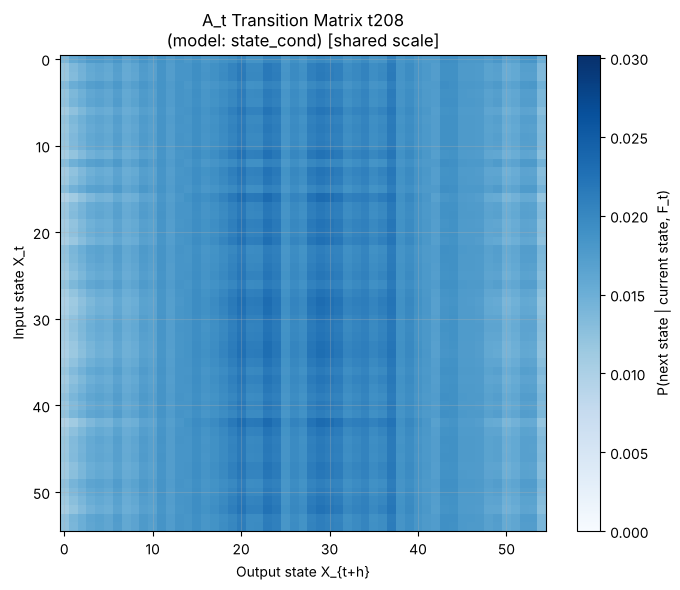

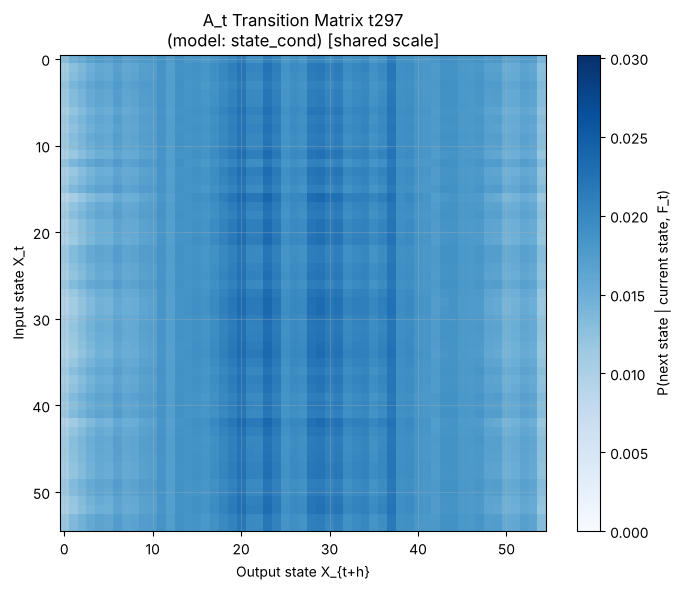

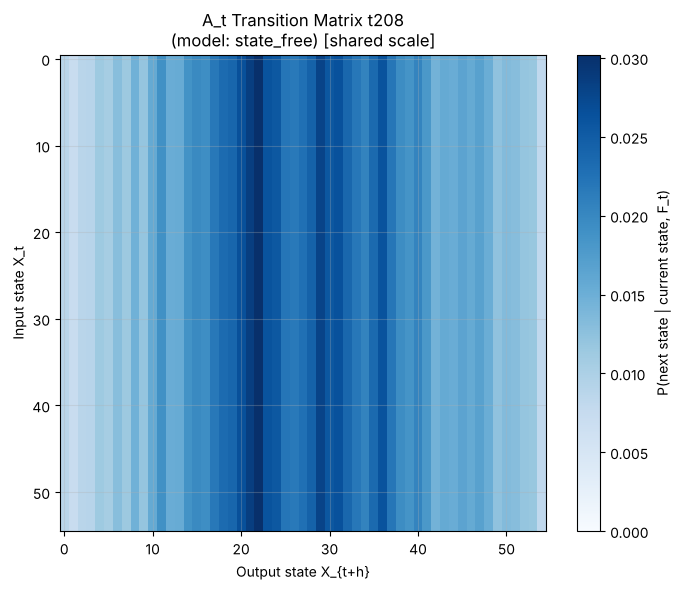

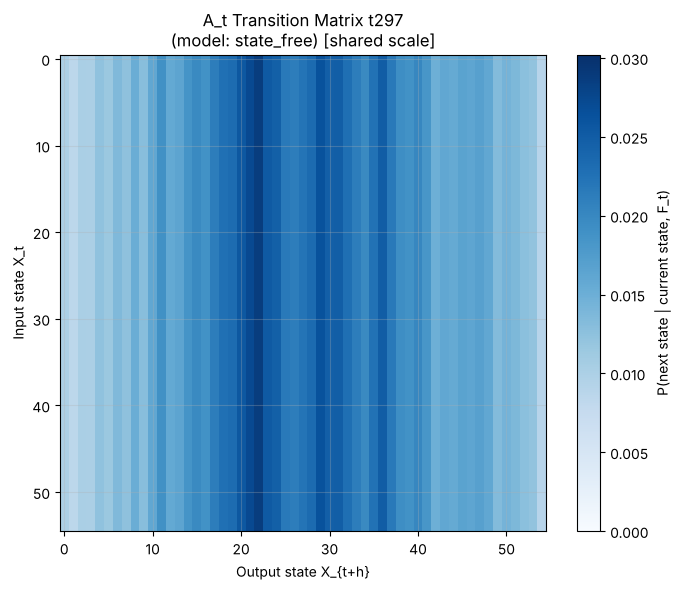

In [9]:
times = [208, 253, 297]
vmax = max(A[(k, 1)][s].max() for k in ["state_cond", "state_free"] for s in times)
for kind in ["state_cond", "state_free"]:
    for s in times:
        heatmap(A[(kind, 1)][s], f"A_t Transition Matrix t{s}\n(model: {kind}) [shared scale]",
                FIG / f"At_heatmap_{kind}_t{s}", vmax=vmax)
        plt.show() if s != 253 else plt.close("all")